### Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load the data

In [2]:
df = pd.read_csv('../data/creditcard.csv')
df.shape

(284807, 31)

### Inspect the first rows

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Class balance: how much fraud is there?

In [4]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

### Visualise the class imbalance

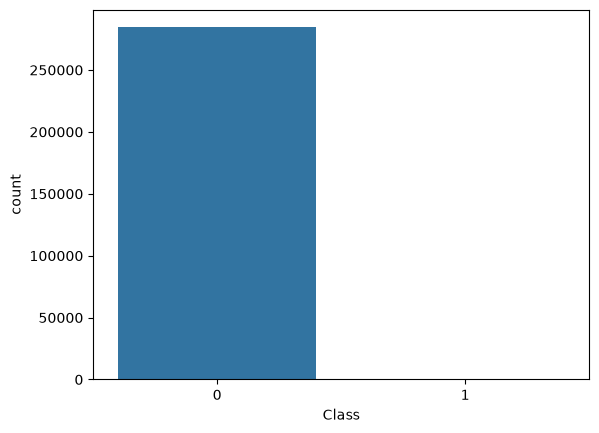

In [5]:
sns.countplot(x='Class', data=df)
plt.show()

### Distribution of transaction amounts

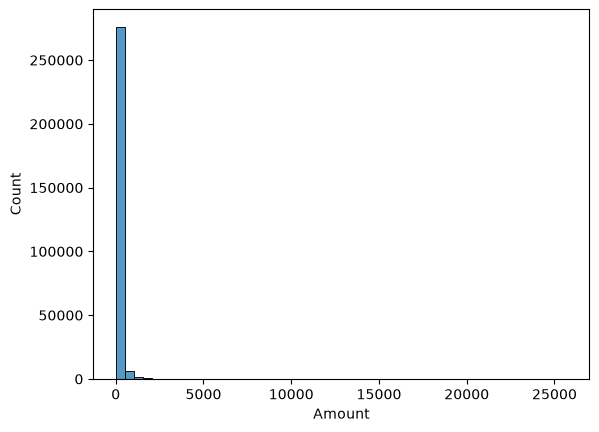

In [6]:
sns.histplot(df['Amount'], bins=50)
plt.show()

### Compare amounts: fraud vs normal

In [7]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


### Chronological train/test split

In [8]:
df = df.sort_values('Time').reset_index(drop=True)
split_index = int(len(df) * 0.8)
train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()
print('Training rows:', len(train), '| fraud cases:', train['Class'].sum())
print('Test rows:', len(test), '| fraud cases:', test['Class'].sum())

Training rows: 227845 | fraud cases: 417
Test rows: 56962 | fraud cases: 75


### Scale Amount and Time (fitted on training data only)

In [9]:
from sklearn.preprocessing import StandardScaler

amount_scaler = StandardScaler()
amount_scaler.fit(train[['Amount']])

time_scaler = StandardScaler()
time_scaler.fit(train[['Time']])

train['Amount_scaled'] = amount_scaler.transform(train[['Amount']])
train['Time_scaled'] = time_scaler.transform(train[['Time']])
test['Amount_scaled'] = amount_scaler.transform(test[['Amount']])
test['Time_scaled'] = time_scaler.transform(test[['Time']])

### Define features (X) and target (y)

In [10]:
v_cols = [col for col in df.columns if col.startswith('V')]
feature_cols = v_cols + ['Amount_scaled', 'Time_scaled']

X_train = train[feature_cols]
y_train = train['Class']
X_test = test[feature_cols]
y_test = test['Class']

### Train Logistic Regression baseline

In [11]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### Evaluate Logistic Regression

In [12]:
from sklearn.metrics import classification_report

lr_pred = lr_model.predict(X_test)
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56887
           1       0.89      0.55      0.68        75

    accuracy                           1.00     56962
   macro avg       0.95      0.77      0.84     56962
weighted avg       1.00      1.00      1.00     56962



### Precision-recall curve and PR-AUC

In [13]:
from sklearn.metrics import precision_recall_curve, auc

lr_scores = lr_model.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, lr_scores)
lr_pr_auc = auc(recall, precision)
print('Logistic Regression PR-AUC:', round(lr_pr_auc, 4))

Logistic Regression PR-AUC: 0.7431


### Plot the precision-recall curve

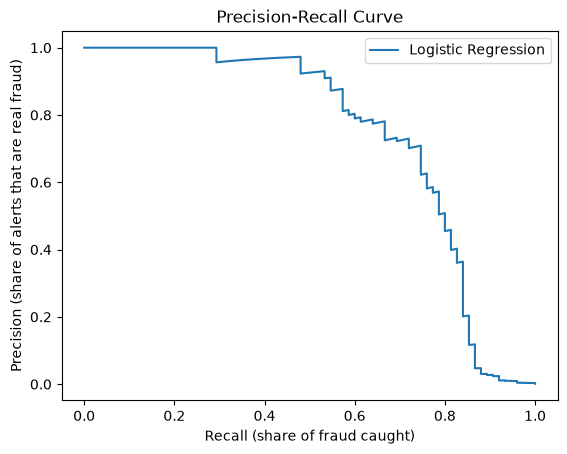

In [14]:
plt.plot(recall, precision, label='Logistic Regression')
plt.xlabel('Recall (share of fraud caught)')
plt.ylabel('Precision (share of alerts that are real fraud)')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

### Threshold comparison (Logistic Regression)

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.1, 0.2, 0.3, 0.5, 0.7]:
    predictions = (lr_scores >= threshold).astype(int)
    print(
        'Threshold', threshold,
        '| precision', round(precision_score(y_test, predictions, zero_division=0), 2),
        '| recall', round(recall_score(y_test, predictions), 2),
        '| F1', round(f1_score(y_test, predictions), 2),
        '| alerts', predictions.sum(),
    )

Threshold 0.1 | precision 0.73 | recall 0.69 | F1 0.71 | alerts 71
Threshold 0.2 | precision 0.78 | recall 0.65 | F1 0.71 | alerts 63
Threshold 0.3 | precision 0.78 | recall 0.61 | F1 0.69 | alerts 59
Threshold 0.5 | precision 0.89 | recall 0.55 | F1 0.68 | alerts 46
Threshold 0.7 | precision 0.97 | recall 0.45 | F1 0.62 | alerts 35


### Train and evaluate XGBoost

In [16]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100, max_depth=4, eval_metric='logloss', random_state=42
)
xgb_model.fit(X_train, y_train)

xgb_scores = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_scores >= 0.5).astype(int)
print(classification_report(y_test, xgb_pred))

p, r, _ = precision_recall_curve(y_test, xgb_scores)
xgb_pr_auc = auc(r, p)
print('XGBoost PR-AUC:', round(xgb_pr_auc, 4))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56887
           1       0.79      0.64      0.71        75

    accuracy                           1.00     56962
   macro avg       0.89      0.82      0.85     56962
weighted avg       1.00      1.00      1.00     56962

XGBoost PR-AUC: 0.6258


### Threshold comparison (XGBoost)

In [17]:
for threshold in [0.1, 0.2, 0.3, 0.5, 0.7]:
    predictions = (xgb_scores >= threshold).astype(int)
    print(
        'Threshold', threshold,
        '| precision', round(precision_score(y_test, predictions, zero_division=0), 2),
        '| recall', round(recall_score(y_test, predictions), 2),
        '| alerts', predictions.sum(),
    )

Threshold 0.1 | precision 0.69 | recall 0.67 | alerts 72
Threshold 0.2 | precision 0.74 | recall 0.67 | alerts 68
Threshold 0.3 | precision 0.78 | recall 0.65 | alerts 63
Threshold 0.5 | precision 0.79 | recall 0.64 | alerts 61
Threshold 0.7 | precision 0.79 | recall 0.61 | alerts 58


### Model comparison: PR curves

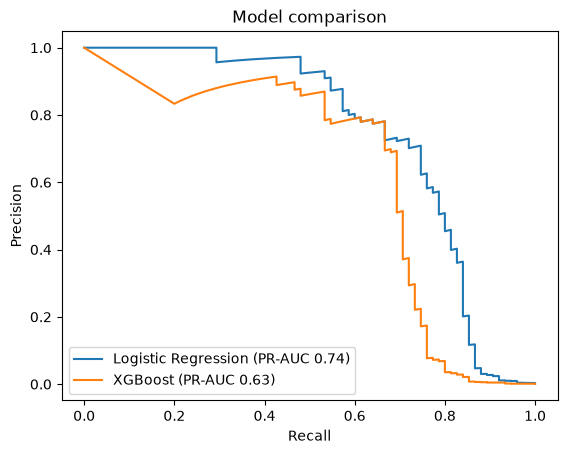

In [18]:
plt.plot(recall, precision, label=f'Logistic Regression (PR-AUC {lr_pr_auc:.2f})')
plt.plot(r, p, label=f'XGBoost (PR-AUC {xgb_pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Model comparison')
plt.legend()
plt.show()

### SHAP: overall feature importance

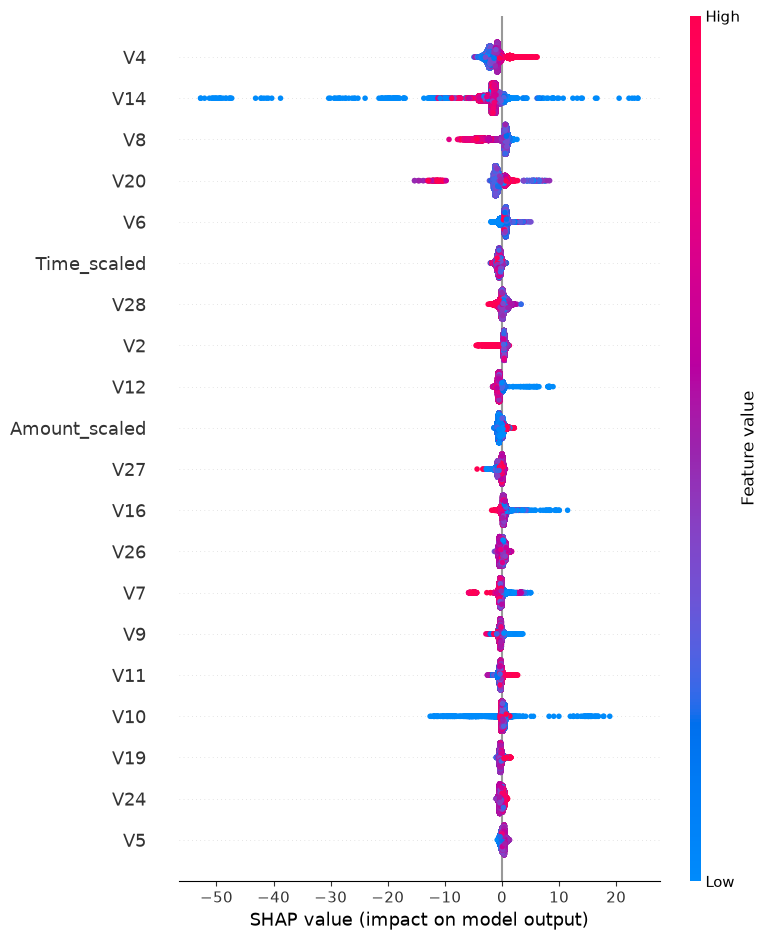

In [19]:
import shap

shap.initjs()
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

### Find fraud cases the model caught and missed

In [20]:
fraud_ids = y_test[y_test == 1].index[:10]

for idx in fraud_ids:
    probability = xgb_model.predict_proba(X_test.loc[[idx]])[0][1]
    print(idx, round(probability, 4))

229712 1.0
229730 0.0713
230076 0.9998
230476 1.0
231978 0.0
233258 0.003
234574 0.4539
234632 1.0
234633 1.0
234705 1.0


### SHAP explainer in probability units

In [21]:
background = X_train.sample(1000, random_state=42)
explainer_prob = shap.TreeExplainer(xgb_model, background, model_output='probability')

Background dataset has 1000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1000 when initializing the masker.


### Explain a caught fraud (transaction 229712)

In [22]:
caught_id = 229712
caught_values = explainer_prob.shap_values(X_test.loc[[caught_id]])
shap.force_plot(explainer_prob.expected_value, caught_values[0], X_test.loc[caught_id])

### Explain a missed fraud (transaction 231978)

In [23]:
missed_id = 231978
missed_values = explainer_prob.shap_values(X_test.loc[[missed_id]])
shap.force_plot(explainer_prob.expected_value, missed_values[0], X_test.loc[missed_id])

### Save the model, features and scalers

In [24]:
import joblib

joblib.dump(xgb_model, '../src/fraud_model.pkl')
joblib.dump(feature_cols, '../src/feature_cols.pkl')
joblib.dump(amount_scaler, '../src/amount_scaler.pkl')
joblib.dump(time_scaler, '../src/time_scaler.pkl')

['../src/time_scaler.pkl']

### Save predictions for the dashboard

In [25]:
THRESHOLD = 0.3

results = test.copy()
results['predicted_proba'] = xgb_model.predict_proba(X_test)[:, 1]
results['predicted_fraud'] = (results['predicted_proba'] >= THRESHOLD).astype(int)
results.to_csv('../data/dashboard_results.csv')
print('Flagged:', results['predicted_fraud'].sum())

Flagged: 63


### Connect to OpenAI

In [26]:
import os
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv('../.env')
client = OpenAI(api_key=os.getenv('OPENAI_API_KEY'))

### Plain-English explanations with GPT

In [27]:
def explain_in_plain_english(transaction_id):
    row = X_test.loc[[transaction_id]]
    probability = xgb_model.predict_proba(row)[0][1]
    values = explainer_prob.shap_values(row)[0]

    pairs = sorted(zip(feature_cols, values), key=lambda pair: abs(pair[1]), reverse=True)
    pairs = pairs[:5]
    top_features = '\n'.join(f'{name}: {value:+.4f}' for name, value in pairs)

    prompt = f"""A fraud detection model gave a transaction a fraud probability
of {probability:.2%}.

The five factors that most influenced this score were (positive pushes towards fraud,
negative pushes away from fraud):
{top_features}

Write a short, plain-English explanation (2-3 sentences) for a bank fraud analyst.

Requirements:
- Mention each factor by name with its value, and say whether it pushed the score up or down.
- These factors are anonymised transaction attributes. Do not guess or invent what they mean.
- Make clear this describes how the model behaved, not proof that the transaction is fraud.
- Do not use technical machine learning jargon.
"""

    response = client.chat.completions.create(
        model='gpt-4o-mini',
        messages=[{'role': 'user', 'content': prompt}],
    )
    return response.choices[0].message.content


print(explain_in_plain_english(229712))

The fraud detection model assessed this transaction with a fraud probability of 100.00%. The factors influencing this score included V14, which increased the score by +0.6116, and V4, which also pushed it up by +0.3578. In contrast, V20 decreased the score by -0.3978, while V12 and V9 contributed positively with +0.2857 and +0.2158, respectively. It's important to note that these factors explain how the model evaluated the transaction, but they do not serve as definitive proof of fraud.
